In [ ]:
# Kmeans


# DBScan


In [ ]:
# Kmeans 

You have n data points. Create k groups out of these.

k = 2

pick 2 random centers. and consider them for grouping.





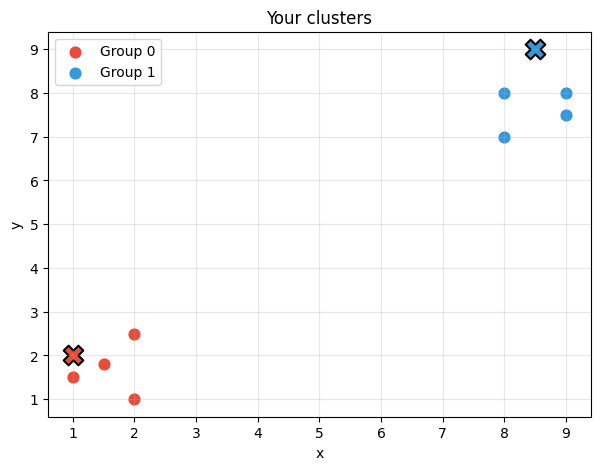

In [3]:
import matplotlib.pyplot as plt

def plot_clusters(groups, centers, title="Clusters"):
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']
    plt.figure(figsize=(7, 5))
    for i, group in enumerate(groups):
        xs = [p[0] for p in group]
        ys = [p[1] for p in group]
        c = colors[i % len(colors)]
        plt.scatter(xs, ys, color=c, s=60, label=f"Group {i}")
        plt.scatter(centers[i][0], centers[i][1], color=c,
                    marker='X', s=200, edgecolors='black', linewidths=1.5)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

groups = [
        [[1, 2], [1, 1.5], [1.5, 1.8], [2, 2.5],[2, 1]], 
        [[8.5, 9], [8, 8], [9, 8], [9, 7.5], [8, 7]]
]

# Use the first two points as initial centers
centers = [groups[0][0],groups[1][0]]

plot_clusters(groups, centers, title="Your clusters")


In [ ]:
# Kmean 

You have n=100 points, you need to group them into k=2 groups.

1. Randomly pick the centers.
2. Separate the points to the group of nearest center.
3. Find new centers 
4. Repeat Step 2. 
    
def group(points, k_num_of_groups):
    # Group these points into k_num_of_groups
    

In [ ]:
You want to group the paragraphs from a novels into 4 groups. 

p1 -> embed1


group(embed1)

In [ ]:
# We have the visiors on our website, clustering them 

Each visitor has the following attributes:
1. Number of Purchases
2. Total number of visits to our website
3. Signup date 
4. average purchase
5. Total purchase
6. Last login time 
7. age 
8. sex 
9. country



In [ ]:
class DB:
    - add_vector(x, data) 
    - index() # (re)create the tree
    - find_closest_vector(x) # return data


In [ ]:
# Create index

# create 8 groups.

for each of these 4 groups:
    create eight groups. 



In [ ]:
# Dimensionaliry Reduction

Q1. We have images data and all of these images have 5px consistent border, can we delete the border?
A: Yes
--
Q2. Let us you have a data:
x1, x2, x3 
x3 = 5*x1 + x2 

A: we can delete x3 

---
Q3: We have one column which has absolutely random data, can we delete it? 
A: Yes. Fooled By randomness. - taleb.

---

Q4: 



In [ ]:
Take MNIST data set. Using PCA do the mensionality reduction. 

1. Find the dimension of maximum variance.
2. Find another dimension of maximum variance orthogonal to 1.
3. Find third dimension which is orthogonal to everything else.
4. ...


Characterstic or features must be orthogonal, meaning there should not overlap.

784 -> 30 pixel


In [6]:
from sklearn.datasets import fetch_openml
import numpy as np
import matplotlib.pyplot as plt

# Download MNIST
mnist = fetch_openml(
    'mnist_784',
    version=1,
    as_frame=False
)

X = mnist.data.astype(np.float32)
y = mnist.target.astype(int)

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])

Dataset shape: (70000, 784)
Number of features: 784


In [8]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X)

# Cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

In [9]:
cumulative_variance

array([0.09746247, 0.16901776, 0.2305141 , 0.2845463 , 0.33342895,
       0.3764817 , 0.40926218, 0.43815857, 0.46574163, 0.48916307,
       0.51022995, 0.53060526, 0.54767585, 0.5646159 , 0.5804496 ,
       0.59531295, 0.60850644, 0.6212964 , 0.63316905, 0.6446984 ,
       0.65535873, 0.6654566 , 0.67504805, 0.68414426, 0.6929771 ,
       0.7013652 , 0.7094634 , 0.71732056, 0.724723  , 0.731623  ,
       0.73818433, 0.744639  , 0.750647  , 0.75650305, 0.76217043,
       0.767605  , 0.77265203, 0.7775228 , 0.7823123 , 0.78698814,
       0.7915318 , 0.79598093, 0.800163  , 0.80412453, 0.8079615 ,
       0.8117193 , 0.8153335 , 0.81882364, 0.82221085, 0.82540774,
       0.82857615, 0.8316775 , 0.83464223, 0.83751315, 0.8403382 ,
       0.84303236, 0.8457162 , 0.8482812 , 0.85081285, 0.85325927,
       0.8556562 , 0.85804194, 0.8603343 , 0.8625437 , 0.86467427,
       0.86673737, 0.8687652 , 0.87071544, 0.8726301 , 0.8745156 ,
       0.87638533, 0.8781863 , 0.8799541 , 0.88168764, 0.88333

In [10]:
for threshold in [0.90, 0.95, 0.99]:
    n_components = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    print(
        f"{threshold:.0%} variance: "
        f"{n_components} components"
    )

90% variance: 87 components
95% variance: 154 components
99% variance: 331 components


 Features  Accuracy  Training Time (s)  Prediction Time (s)
      784  0.915571           9.131641             0.046578
      600  0.917143          13.027157             0.023775
      500  0.920429          12.775706             0.018474
      400  0.921643          11.701409             0.010328
      350  0.922429          17.205448             0.030864
      150  0.921429          13.575804             0.013772
      100  0.916929           7.265092             0.009059
       50  0.905714           3.488687             0.004482
       30  0.894071           3.222941             0.001460


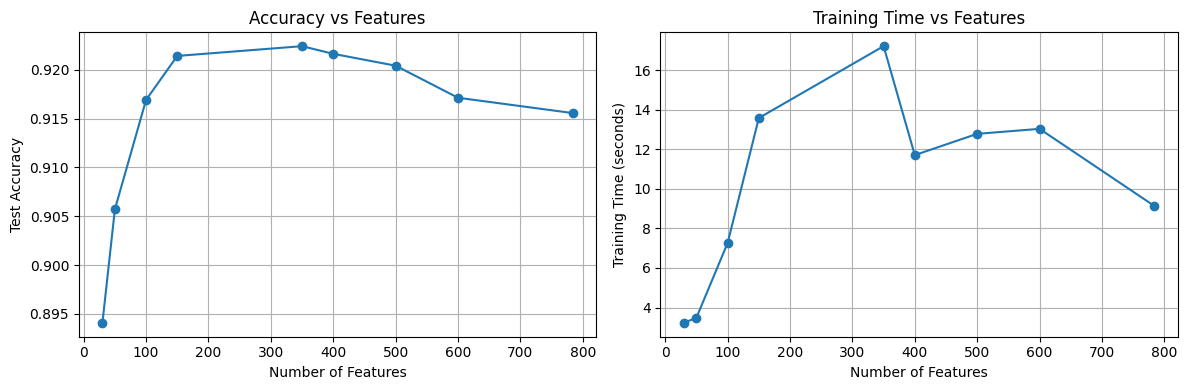

In [14]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# 1. Download MNIST
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

X = mnist.data
y = mnist.target.astype(int)

# 2. Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Train classifiers with different dimensions
results = []

for n_components in [784, 600, 500, 400, 350, 150, 100, 50, 30]:

    start = time.time()

    if n_components == 784:
        X_train_reduced = X_train
        X_test_reduced = X_test
    else:
        pca = PCA(n_components=n_components, random_state=42)

        X_train_reduced = pca.fit_transform(X_train)
        X_test_reduced = pca.transform(X_test)

    # Train classifier
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_reduced, y_train)

    training_time = time.time() - start

    # Predict
    start = time.time()
    y_pred = model.predict(X_test_reduced)
    prediction_time = time.time() - start

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Features": n_components,
        "Accuracy": accuracy,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

# 5. Compare results
df = pd.DataFrame(results)
print(df.to_string(index=False))

# 6. Visualize results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df["Features"], df["Accuracy"], marker="o")
axes[0].set_xlabel("Number of Features")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Accuracy vs Features")
axes[0].grid(True)

axes[1].plot(
    df["Features"],
    df["Training Time (s)"],
    marker="o"
)
axes[1].set_xlabel("Number of Features")
axes[1].set_ylabel("Training Time (seconds)")
axes[1].set_title("Training Time vs Features")
axes[1].grid(True)

plt.tight_layout()
plt.show()

 Features  Train Accuracy  Test Accuracy  Training Time (s)  Prediction Time (s)
      100        0.921089       0.916929           3.096292             0.001559
      150        0.928536       0.921429           4.800157             0.006128
      200        0.931411       0.922643           4.941168             0.004382
      250        0.933768       0.921786           5.325286             0.002973
      300        0.936232       0.922643           6.100650             0.008326
      350        0.936518       0.922429           5.784387             0.011295
      400        0.937661       0.921643           5.453048             0.006172
      500        0.940750       0.920429           6.254498             0.010242
      600        0.942875       0.917143           7.804143             0.008382
      784        0.945429       0.915571           6.357760             0.039986


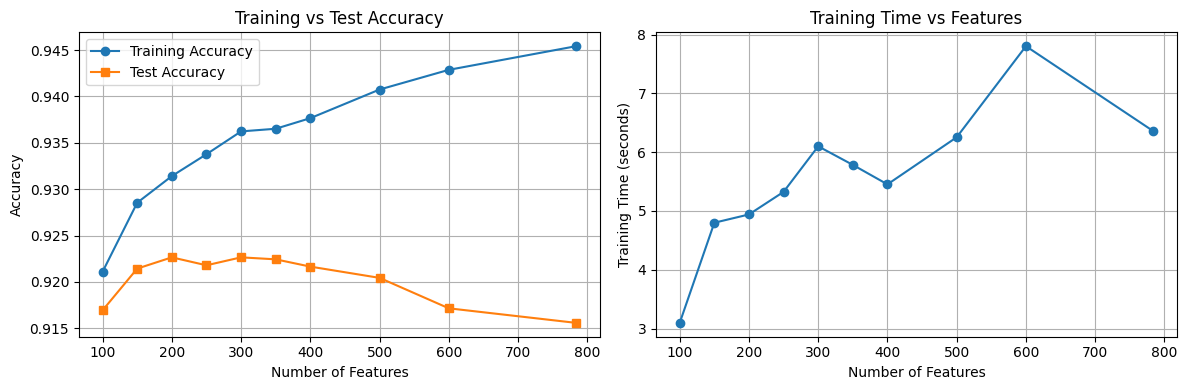

In [16]:
# 4. Train classifiers with different dimensions
results = []

for n_components in [784, 600, 500, 400, 350, 300, 250, 200, 150, 100]:

    start = time.time()

    if n_components == 784:
        X_train_reduced = X_train
        X_test_reduced = X_test
    else:
        pca = PCA(n_components=n_components, random_state=42)
        X_train_reduced = pca.fit_transform(X_train)
        X_test_reduced = pca.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_reduced, y_train)

    training_time = time.time() - start

    # Training accuracy
    y_train_pred = model.predict(X_train_reduced)
    train_accuracy = accuracy_score(y_train, y_train_pred)

    # Test accuracy
    start = time.time()
    y_test_pred = model.predict(X_test_reduced)
    prediction_time = time.time() - start

    test_accuracy = accuracy_score(y_test, y_test_pred)

    results.append({
        "Features": n_components,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

# 5. Compare results
df = pd.DataFrame(results).sort_values("Features")
print(df.to_string(index=False))

# 6. Plot training and test accuracy together
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    df["Features"],
    df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    df["Features"],
    df["Test Accuracy"],
    marker="s",
    label="Test Accuracy"
)

axes[0].set_xlabel("Number of Features")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Training vs Test Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    df["Features"],
    df["Training Time (s)"],
    marker="o"
)
axes[1].set_xlabel("Number of Features")
axes[1].set_ylabel("Training Time (seconds)")
axes[1].set_title("Training Time vs Features")
axes[1].grid(True)

plt.tight_layout()
plt.show()

https://chatgpt.com/share/6ad4461f-57d4-83ea-b993-028f51c2d882

In [ ]:
# Exercise - Pick a read dataset on regression 
# and then demonstrate the test/train accuracy on different features.


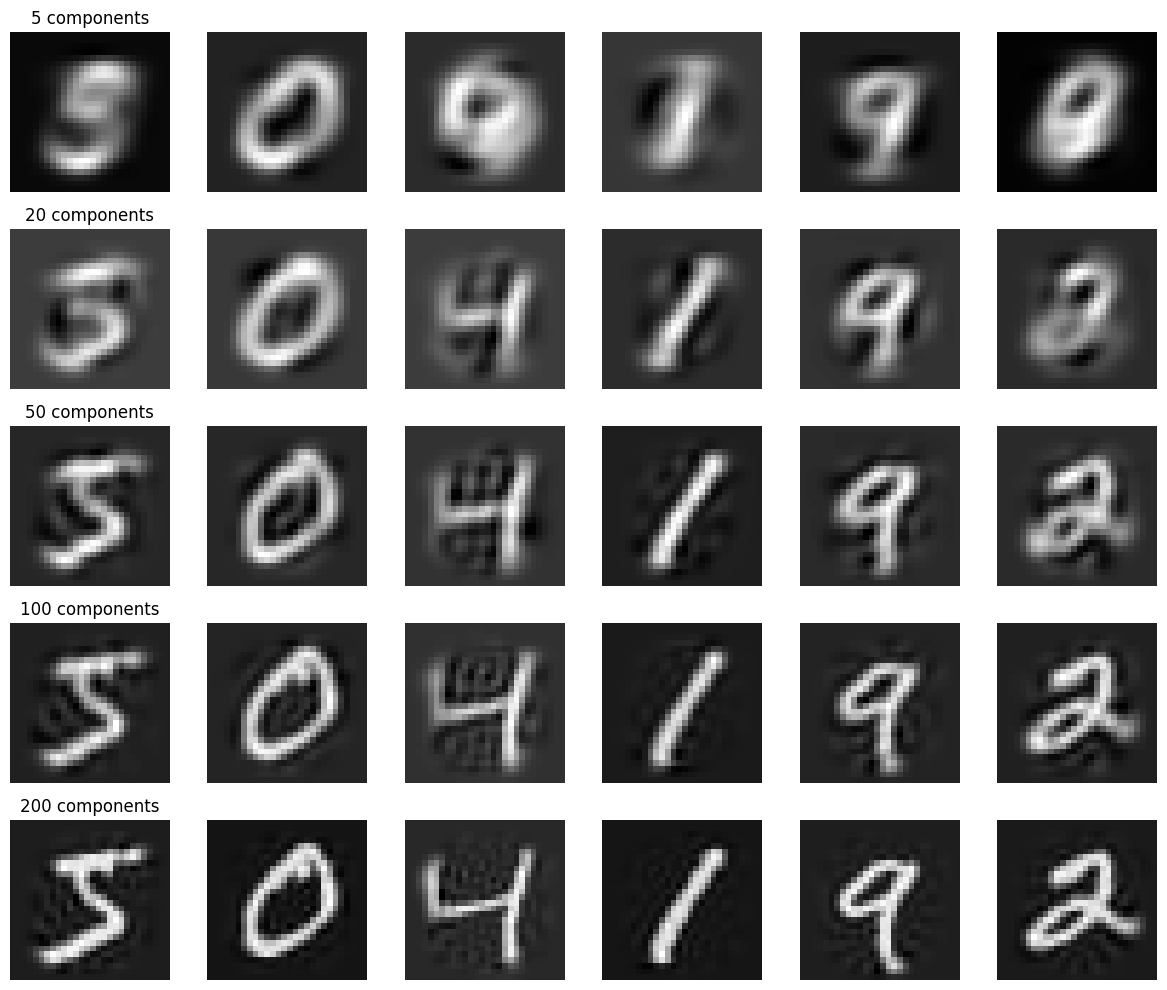

In [18]:
fig, axes = plt.subplots(5, 6, figsize=(12, 10))

for row, n in enumerate([5, 20, 50, 100, 200]):
    pca = PCA(n_components=n, random_state=42)

    X_small = pca.fit_transform(X)
    X_restored = pca.inverse_transform(X_small)

    for col in range(6):
        axes[row, col].imshow(
            X_restored[col].reshape(28, 28),
            cmap='gray'
        )
        axes[row, col].axis('off')

        if col == 0:
            axes[row, col].set_title(f"{n} components")

plt.tight_layout()
plt.show()

Images: (70000, 784)
Labels: (70000,)


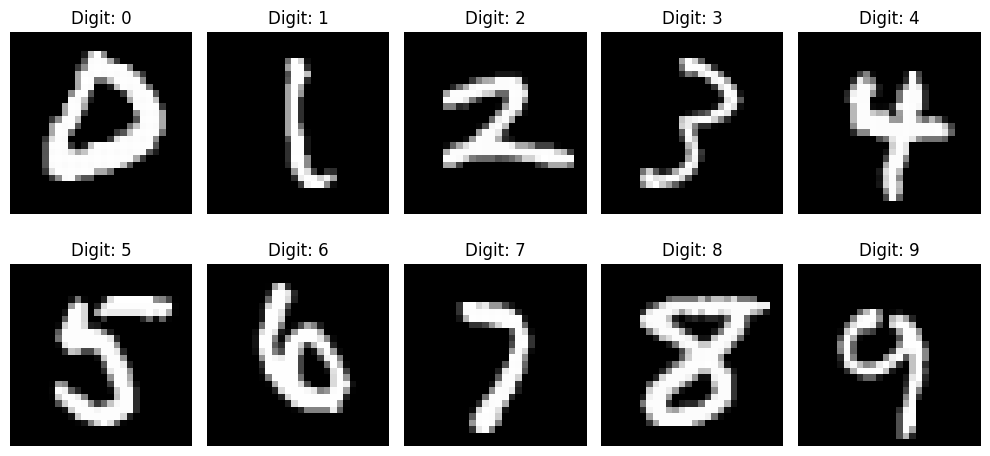

In [22]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Download MNIST
mnist = fetch_openml(
    "mnist_784", version=1, as_frame=False
)

X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape)

# Use a subset for faster experiments
rng = np.random.RandomState(42)
indices = rng.choice(len(X), 10000, replace=False)

X = X[indices]
y = y[indices]

# Display sample digits
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit, ax in enumerate(axes.flat):
    idx = np.where(y == digit)[0][0]
    ax.imshow(X[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Original shape: (10000, 784)
Reduced shape: (10000, 2)


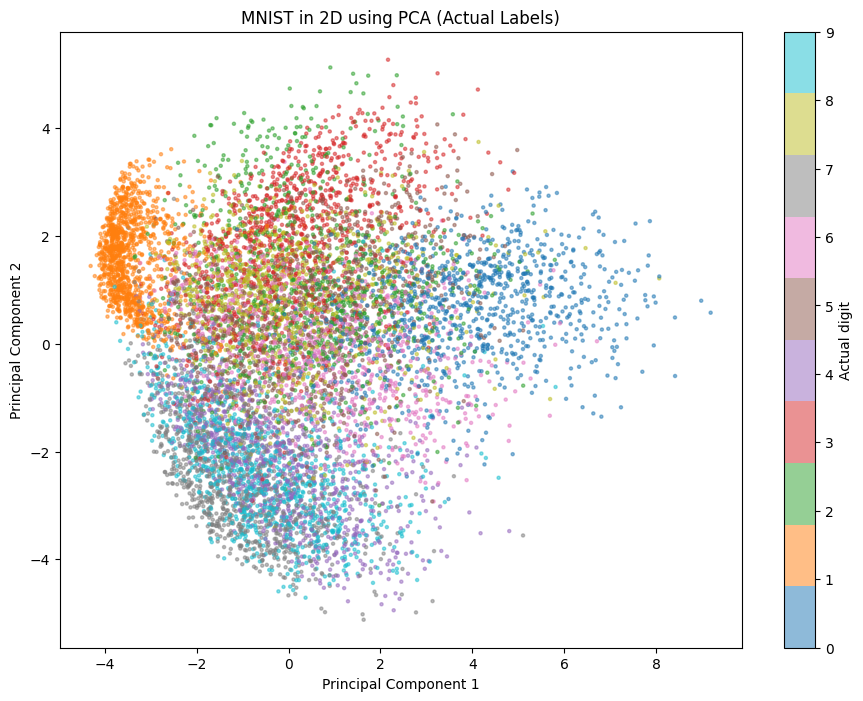

In [23]:

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)

print("Original shape:", X.shape)
print("Reduced shape:", X_2d.shape)

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y,
    cmap="tab10",
    s=5,
    alpha=0.5
)

plt.colorbar(scatter, ticks=range(10), label="Actual digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("MNIST in 2D using PCA (Actual Labels)")
plt.show()


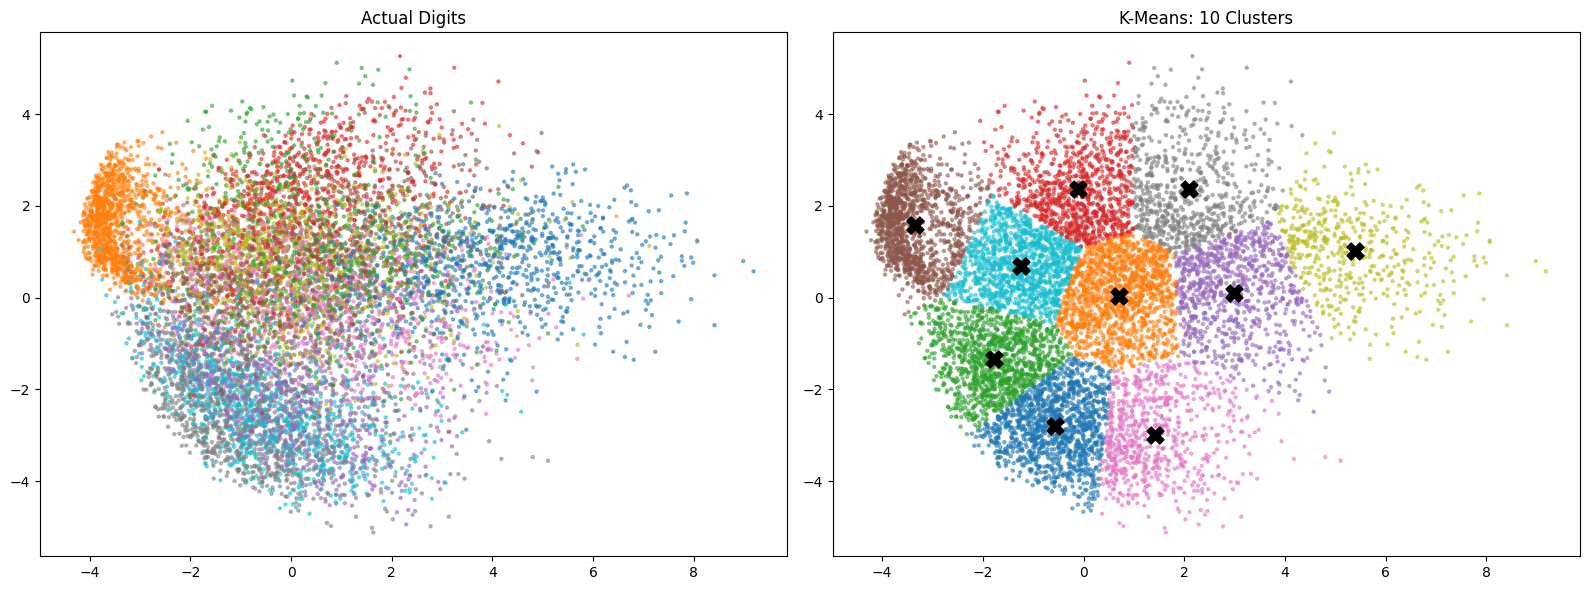

In [24]:

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_2d)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=y, cmap="tab10", s=5, alpha=0.5
)
axes[0].set_title("Actual Digits")

axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=clusters, cmap="tab10", s=5, alpha=0.5
)
axes[1].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="black", marker="X", s=150
)
axes[1].set_title("K-Means: 10 Clusters")

plt.tight_layout()
plt.show()


In [25]:

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    SpectralClustering,
    Birch
)
from sklearn.mixture import GaussianMixture

# Use the same subset for every algorithm
X_small = X_2d[:3000]
y_small = y[:3000]

models = {
    "K-Means": KMeans(
        n_clusters=10, n_init=10, random_state=42
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=10, random_state=42
    ),

    "Agglomerative": AgglomerativeClustering(
        n_clusters=10
    ),

    "Spectral": SpectralClustering(
        n_clusters=10,
        affinity="nearest_neighbors",
        n_neighbors=15,
        assign_labels="kmeans",
        random_state=42
    ),

    "Birch": Birch(n_clusters=10)
}

results = {}

for name, model in models.items():
    print("Training:", name)
    results[name] = model.fit_predict(X_small)


Training: K-Means
Training: Gaussian Mixture
Training: Agglomerative
Training: Spectral
Training: Birch


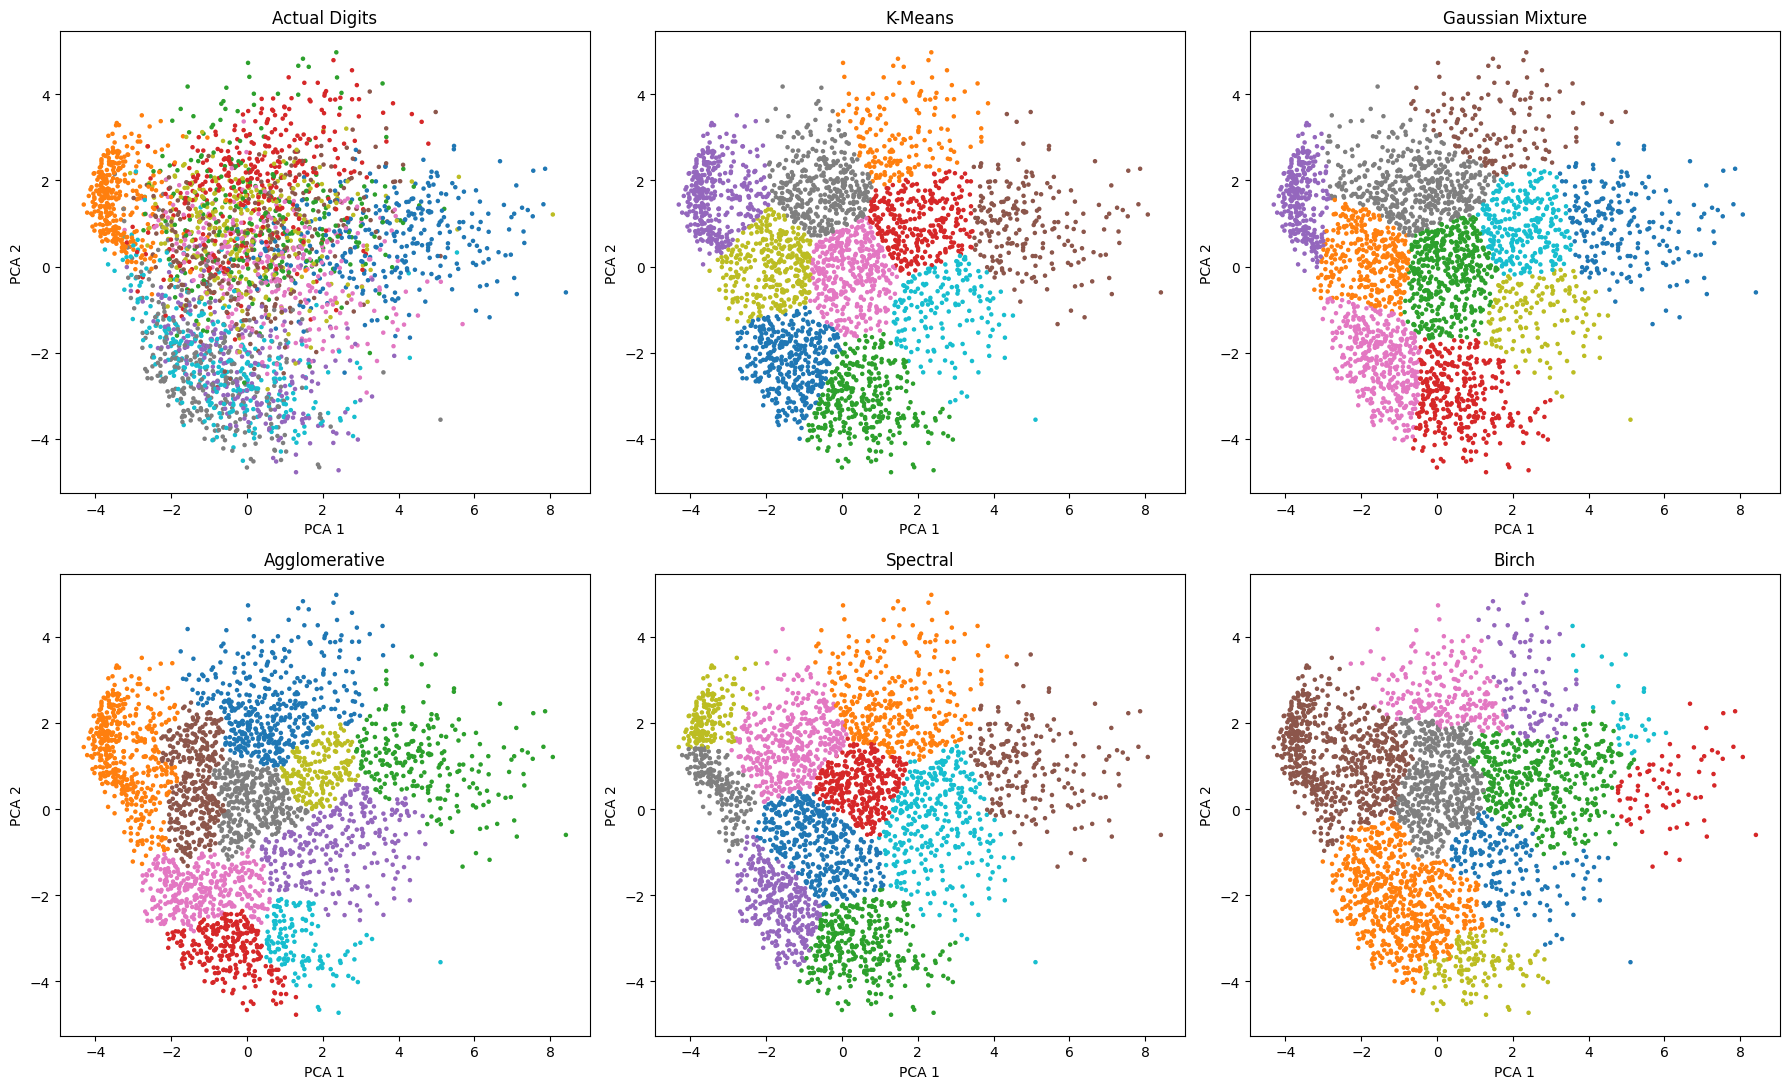

In [26]:

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

# Ground truth
axes[0].scatter(
    X_small[:, 0], X_small[:, 1],
    c=y_small, cmap="tab10", s=5
)
axes[0].set_title("Actual Digits")

# Unsupervised algorithms
for ax, (name, labels) in zip(axes[1:], results.items()):
    ax.scatter(
        X_small[:, 0],
        X_small[:, 1],
        c=labels,
        cmap="tab10",
        s=5
    )
    ax.set_title(name)

for ax in axes:
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

plt.tight_layout()
plt.show()


          Algorithm    ARI    NMI  Homogeneity
0           K-Means  0.246  0.362        0.359
2     Agglomerative  0.243  0.345        0.341
1  Gaussian Mixture  0.233  0.368        0.363
4             Birch  0.212  0.336        0.313
3          Spectral  0.203  0.361        0.359


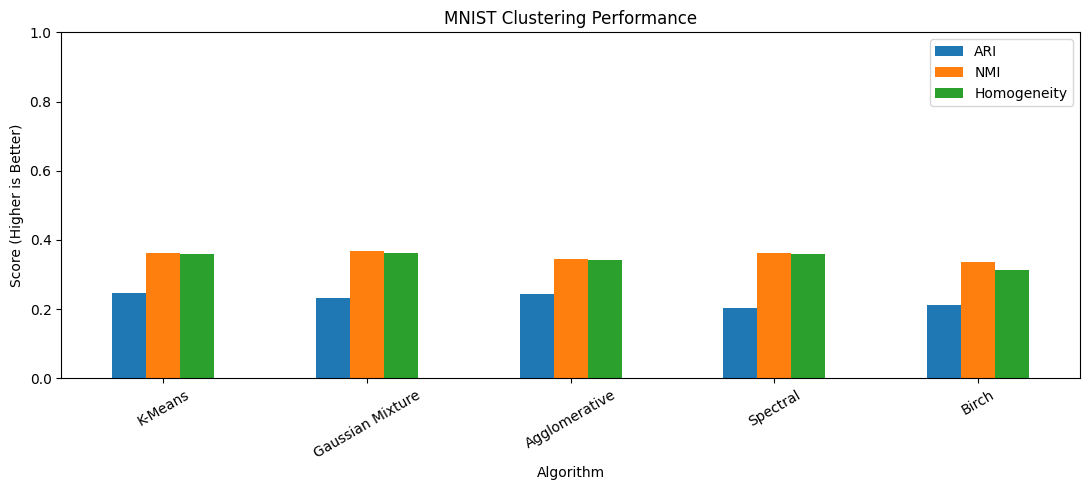

In [27]:

import pandas as pd

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score
)

scores = []

for name, clusters in results.items():
    scores.append({
        "Algorithm": name,
        "ARI": adjusted_rand_score(y_small, clusters),
        "NMI": normalized_mutual_info_score(y_small, clusters),
        "Homogeneity": homogeneity_score(y_small, clusters)
    })

df = pd.DataFrame(scores)
print(df.sort_values("ARI", ascending=False).round(3))

df.set_index("Algorithm").plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=30
)

plt.title("MNIST Clustering Performance")
plt.ylabel("Score (Higher is Better)")
plt.tight_layout()
plt.show()


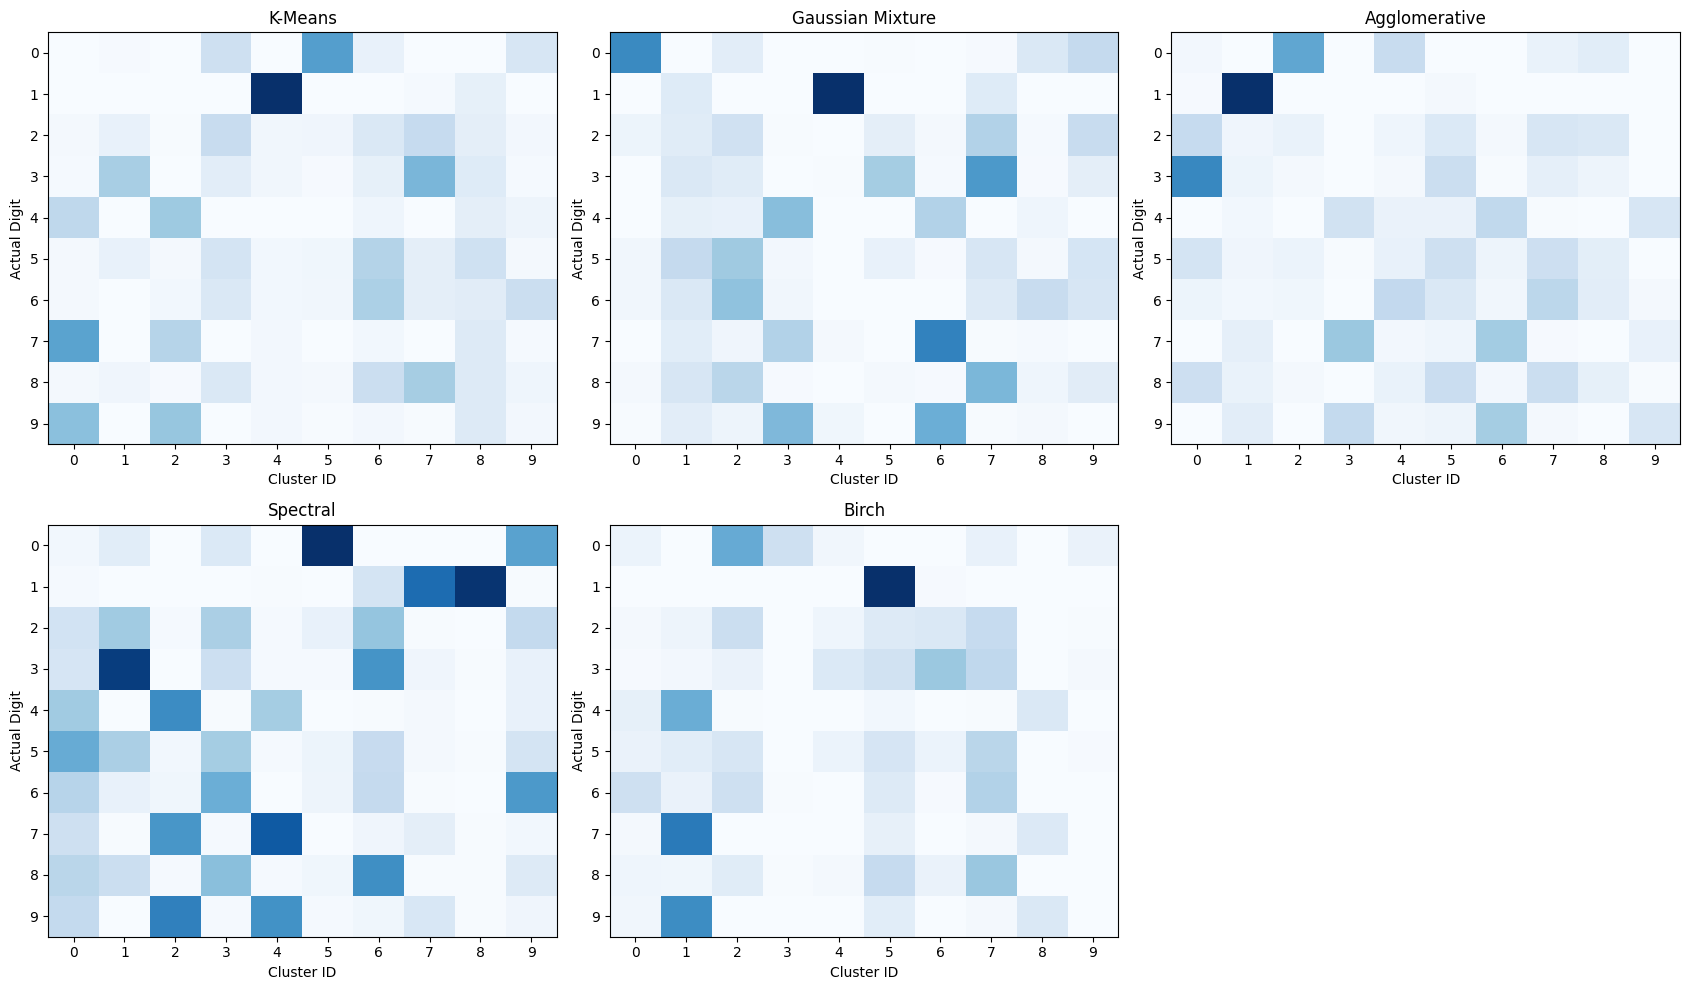

In [28]:

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for ax, (name, clusters) in zip(axes, results.items()):
    # Rows = actual digits, columns = cluster IDs
    counts = pd.crosstab(
        pd.Series(y_small, name="Digit"),
        pd.Series(clusters, name="Cluster")
    )

    ax.imshow(counts.values, cmap="Blues", aspect="auto")
    ax.set_title(name)
    ax.set_xlabel("Cluster ID")
    ax.set_ylabel("Actual Digit")
    ax.set_xticks(range(len(counts.columns)))
    ax.set_xticklabels(counts.columns)
    ax.set_yticks(range(10))

axes[-1].axis("off")

plt.tight_layout()
plt.show()


2 dimensions: ARI=0.246, NMI=0.368
10 dimensions: ARI=0.363, NMI=0.478
50 dimensions: ARI=0.366, NMI=0.491
100 dimensions: ARI=0.370, NMI=0.499
200 dimensions: ARI=0.373, NMI=0.501


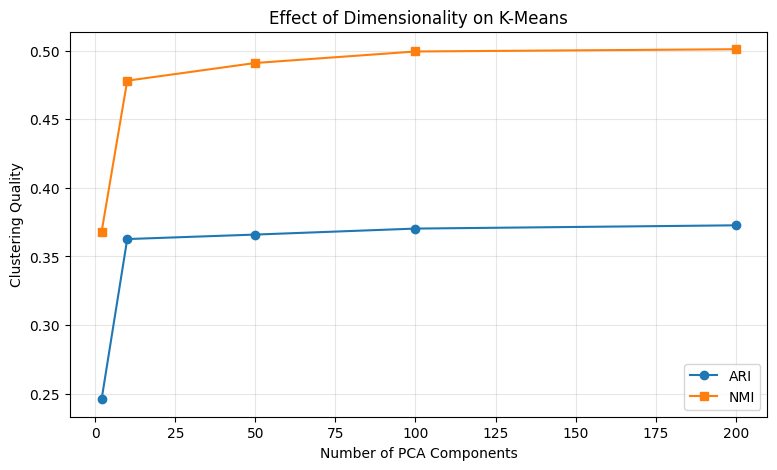

In [29]:

# Use the original pixel data for the same 3000 samples
X_original = X[:3000]
y_original = y[:3000]

dimensions = [2, 10, 50, 100, 200]
ari_scores = []
nmi_scores = []

for dim in dimensions:
    pca = PCA(
        n_components=dim,
        random_state=42
    )
    X_reduced = pca.fit_transform(X_original)

    model = KMeans(
        n_clusters=10,
        random_state=42,
        n_init=10
    )

    clusters = model.fit_predict(X_reduced)

    ari = adjusted_rand_score(y_original, clusters)
    nmi = normalized_mutual_info_score(y_original, clusters)

    ari_scores.append(ari)
    nmi_scores.append(nmi)

    print(f"{dim} dimensions: ARI={ari:.3f}, NMI={nmi:.3f}")

plt.figure(figsize=(9, 5))
plt.plot(dimensions, ari_scores, "o-", label="ARI")
plt.plot(dimensions, nmi_scores, "s-", label="NMI")

plt.xlabel("Number of PCA Components")
plt.ylabel("Clustering Quality")
plt.title("Effect of Dimensionality on K-Means")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


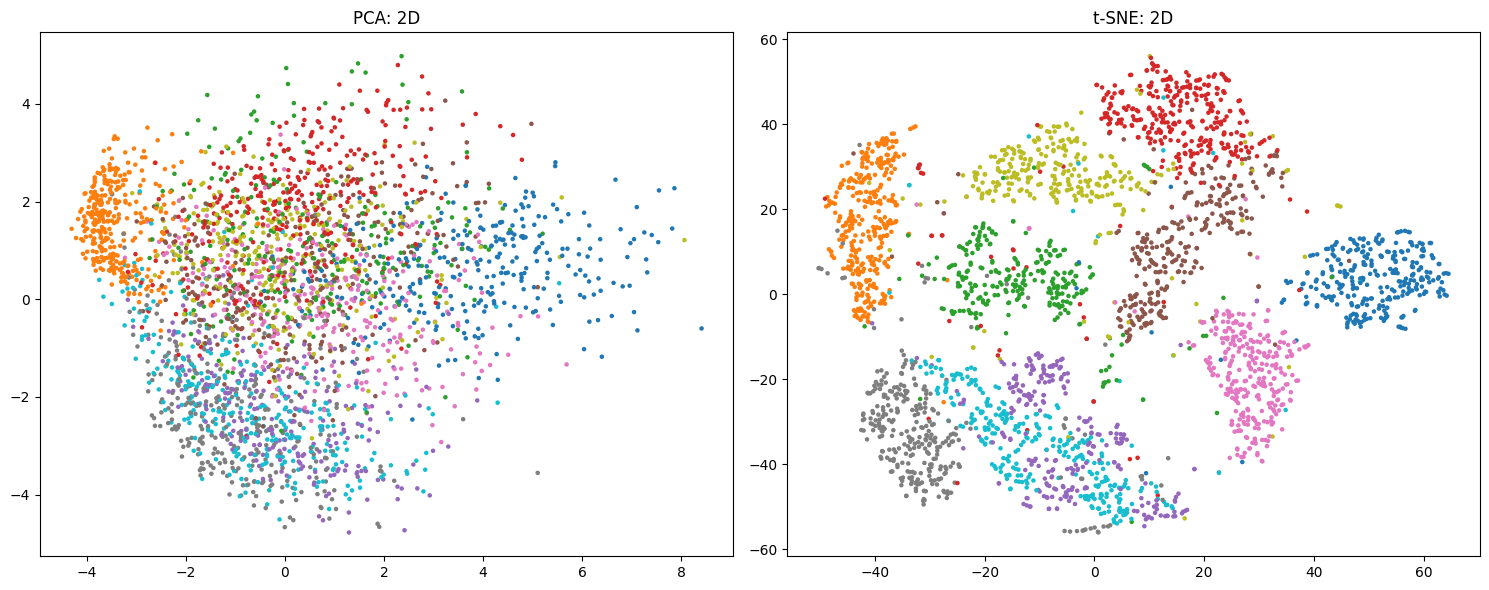

In [30]:

from sklearn.manifold import TSNE

# Reduce to 50D first to speed up t-SNE
X_50 = PCA(
    n_components=50, random_state=42
).fit_transform(X_original)

X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
).fit_transform(X_50)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(
    X_small[:, 0], X_small[:, 1],
    c=y_small, cmap="tab10", s=5
)
axes[0].set_title("PCA: 2D")

axes[1].scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_original, cmap="tab10", s=5
)
axes[1].set_title("t-SNE: 2D")

plt.tight_layout()
plt.show()


In [32]:
# https://chatgpt.com/share/6ad44ffc-a398-83ea-8472-1d8657b836e8

In [31]:
# X -> PCA -> TSNE -> Kmeans -> label each group 
